In [9]:
import os, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

df = pd.read_csv('data_banknote_authentication.txt', header=None, names=['variance', 'skewness', 'kurtosis', 'entropy', 'class'])
print(df.shape)
print(df['class'].value_counts())

X = df[['variance', 'skewness', 'kurtosis', 'entropy']].values
y = df['class'].values

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def scale_fit(Xtrain):                      # training-set statistics only
    return Xtrain.mean(axis=0), Xtrain.std(axis=0)
def scale_apply(Xa, mu, sd):
    return (Xa - mu) / sd

(1372, 5)
class
0    762
1    610
Name: count, dtype: int64


In [10]:
CMAP_BG = ListedColormap(["#cfe8f3", "#fde2b3"])
CMAP_PT = ListedColormap(["#1f77b4", "#ff7f0e"])

def _grid(X, pad=0.5, n=300):
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-pad, X[:,0].max()+pad, n),
                         np.linspace(X[:,1].min()-pad, X[:,1].max()+pad, n))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()]

def plot_boundary(model, X, y, ax, title="", xl="", yl="", pos=1):
    xx, yy, G = _grid(X)
    Z = (model.predict(G) == pos).astype(int).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.8, cmap=CMAP_BG, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[:,0], X[:,1], c=(np.asarray(y)==pos).astype(int), cmap=CMAP_PT, edgecolor="k", s=18, linewidth=0.3)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

def plot_margins(score_fn, X, y, ax, title="", xl="", yl="", violators=None):
    xx, yy, G = _grid(X)
    F = score_fn(G).reshape(xx.shape)
    ax.contourf(xx, yy, (F >= 0).astype(int), alpha=0.6, cmap=CMAP_BG, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, F, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(X[:,0], X[:,1], c=(np.asarray(y)==1).astype(int), cmap=CMAP_PT, edgecolor="k", s=18, linewidth=0.3)
    if violators is not None and violators.any():
        ax.scatter(X[violators,0], X[violators,1], s=90, facecolors="none", edgecolors="red",
                   linewidths=1.2, label=f"margin violators ({violators.sum()})")
        ax.legend(fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

## Part A
### Manual and sklearn accuracy and agreement; the tree’s split rules; train accuracy rising with depth while test accuracy plateaus (overfitting); gini vs entropy.

### Decision Tree from Scratch

In [11]:
def gini(y, k=2):
    if len(y) == 0: return 0.0
    p = np.bincount(y, minlength=k) / len(y)
    return 1.0 - np.sum(p**2)

def entropy(y, k=2):
    if len(y) == 0: return 0.0
    p = np.bincount(y, minlength=k) / len(y)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def _imp_counts(counts, crit):              # vectorised impurity from class counts
    p = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
    if crit == "gini":
        return 1.0 - np.sum(p**2, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        lp = np.where(p > 0, np.log2(p), 0.0)
    return -np.sum(p * lp, axis=1)

class Node:
    def __init__(self, depth):
        self.depth = depth; self.feature = None; self.threshold = None
        self.left = None; self.right = None
        self.value = None; self.counts = None; self.impurity = None; self.n = 0
    @property
    def is_leaf(self): return self.left is None

class DecisionTreeScratch:
    def __init__(self, criterion="gini", max_depth=5, min_samples_split=2, min_samples_leaf=1):
        self.criterion, self.max_depth = criterion, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf

    def fit(self, X, y, feature_names=None):
        X, y = np.asarray(X, float), np.asarray(y, int)
        self.k = int(y.max()) + 1
        self.names = feature_names or [f"x{i}" for i in range(X.shape[1])]
        self.root = self._grow(X, y, 0)
        return self

    def _imp(self, y):
        return (gini if self.criterion == "gini" else entropy)(y, self.k)

    def _best_split(self, X, y, parent_imp):
        n, best = len(y), (None, None, 0.0)
        onehot = np.eye(self.k)[y]
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="mergesort")
            xs, oh = X[order, j], onehot[order]
            left = np.cumsum(oh, axis=0)[:-1]
            right = oh.sum(axis=0) - left
            nl = np.arange(1, n); nr = n - nl
            valid = (xs[1:] > xs[:-1]) & (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf)
            if not valid.any(): continue
            w = (nl * _imp_counts(left, self.criterion) + nr * _imp_counts(right, self.criterion)) / n
            gain = parent_imp - w
            gain[~valid] = -np.inf
            i = int(np.argmax(gain))
            if gain[i] > best[2] + 1e-12:
                best = (j, (xs[i] + xs[i+1]) / 2, float(gain[i]))   # midpoint threshold
        return best

    def _grow(self, X, y, depth):
        node = Node(depth)
        node.n = len(y); node.counts = np.bincount(y, minlength=self.k)
        node.value = int(np.argmax(node.counts)); node.impurity = self._imp(y)
        if depth >= self.max_depth or len(y) < self.min_samples_split or node.impurity == 0:
            return node                                             # stopping rules
        j, thr, gain = self._best_split(X, y, node.impurity)
        if j is None: return node
        mask = X[:, j] <= thr
        node.feature, node.threshold = j, thr
        node.left = self._grow(X[mask], y[mask], depth + 1)
        node.right = self._grow(X[~mask], y[~mask], depth + 1)
        return node

    def predict(self, X):
        out = []
        for x in np.asarray(X, float):
            n = self.root
            while not n.is_leaf:
                n = n.left if x[n.feature] <= n.threshold else n.right
            out.append(n.value)
        return np.array(out, dtype=int)

    def depth(self):
        f = lambda n: 0 if n.is_leaf else 1 + max(f(n.left), f(n.right))
        return f(self.root)
    def n_leaves(self):
        f = lambda n: 1 if n.is_leaf else f(n.left) + f(n.right)
        return f(self.root)

    def rules(self, cls=("genuine", "forged")):
        lines = []
        def rec(n, ind):
            pad = "|   " * ind
            if n.is_leaf:
                lines.append(f"{pad}|--- class: {cls[n.value]} (n={n.n}, counts={n.counts.tolist()})"); return
            lines.append(f"{pad}|--- {self.names[n.feature]} <= {n.threshold:.4f}"); rec(n.left, ind+1)
            lines.append(f"{pad}|--- {self.names[n.feature]} >  {n.threshold:.4f}"); rec(n.right, ind+1)
        rec(self.root, 0)
        return "\n".join(lines)

    def plot_tree(self, cls=("genuine", "forged")):
        pos, c = {}, [0]
        def layout(n):
            if n.is_leaf: pos[id(n)] = (c[0], -n.depth); c[0] += 1
            else:
                layout(n.left); layout(n.right)
                pos[id(n)] = ((pos[id(n.left)][0] + pos[id(n.right)][0]) / 2, -n.depth)
        layout(self.root)
        fig, ax = plt.subplots(figsize=(max(8, 2*self.n_leaves()), 2.2*(self.depth()+1)))
        col = ["#8ecae6", "#ffb703"]
        def draw(n):
            x, yy = pos[id(n)]
            if n.is_leaf:
                t = f"{self.criterion}={n.impurity:.3f}\nn={n.n}\n{n.counts.tolist()}\n{cls[n.value]}"
            else:
                t = f"{self.names[n.feature]} <= {n.threshold:.3f}\n{self.criterion}={n.impurity:.3f}\nn={n.n}\n{n.counts.tolist()}"
                for ch, lab in ((n.left, "True"), (n.right, "False")):
                    cx, cy = pos[id(ch)]
                    ax.annotate("", xy=(cx, cy+0.18), xytext=(x, yy-0.18), arrowprops=dict(arrowstyle="-", color="gray"))
                    ax.text((x+cx)/2, (yy+cy)/2, lab, fontsize=7, color="gray", ha="center")
                draw(n.left); draw(n.right)
            ax.text(x, yy, t, ha="center", va="center", fontsize=7, bbox=dict(boxstyle="round", fc=col[n.value], ec="k", alpha=.85))
        draw(self.root)
        ax.set_xlim(-0.8, c[0]-0.2); ax.set_ylim(-self.depth()-0.6, 0.6); ax.axis("off")
        ax.set_title(f"Manual decision tree ({self.criterion}, depth={self.depth()})")
        return fig

### Experiments on Variance and Skewness

0.5 1.0
manual acc 0.9345454545454546 | sklearn acc 0.9345454545454546 | agreement 1.0


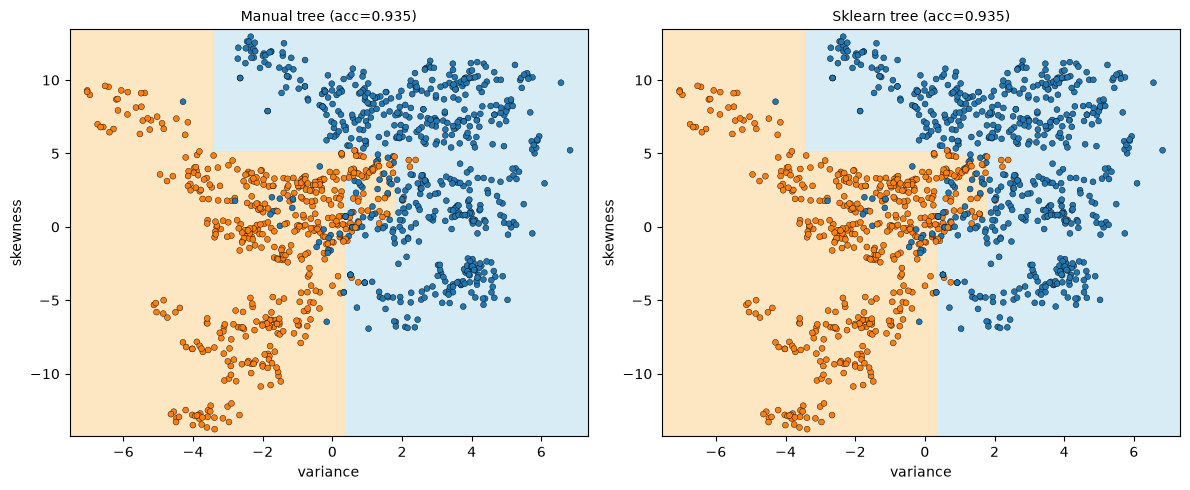

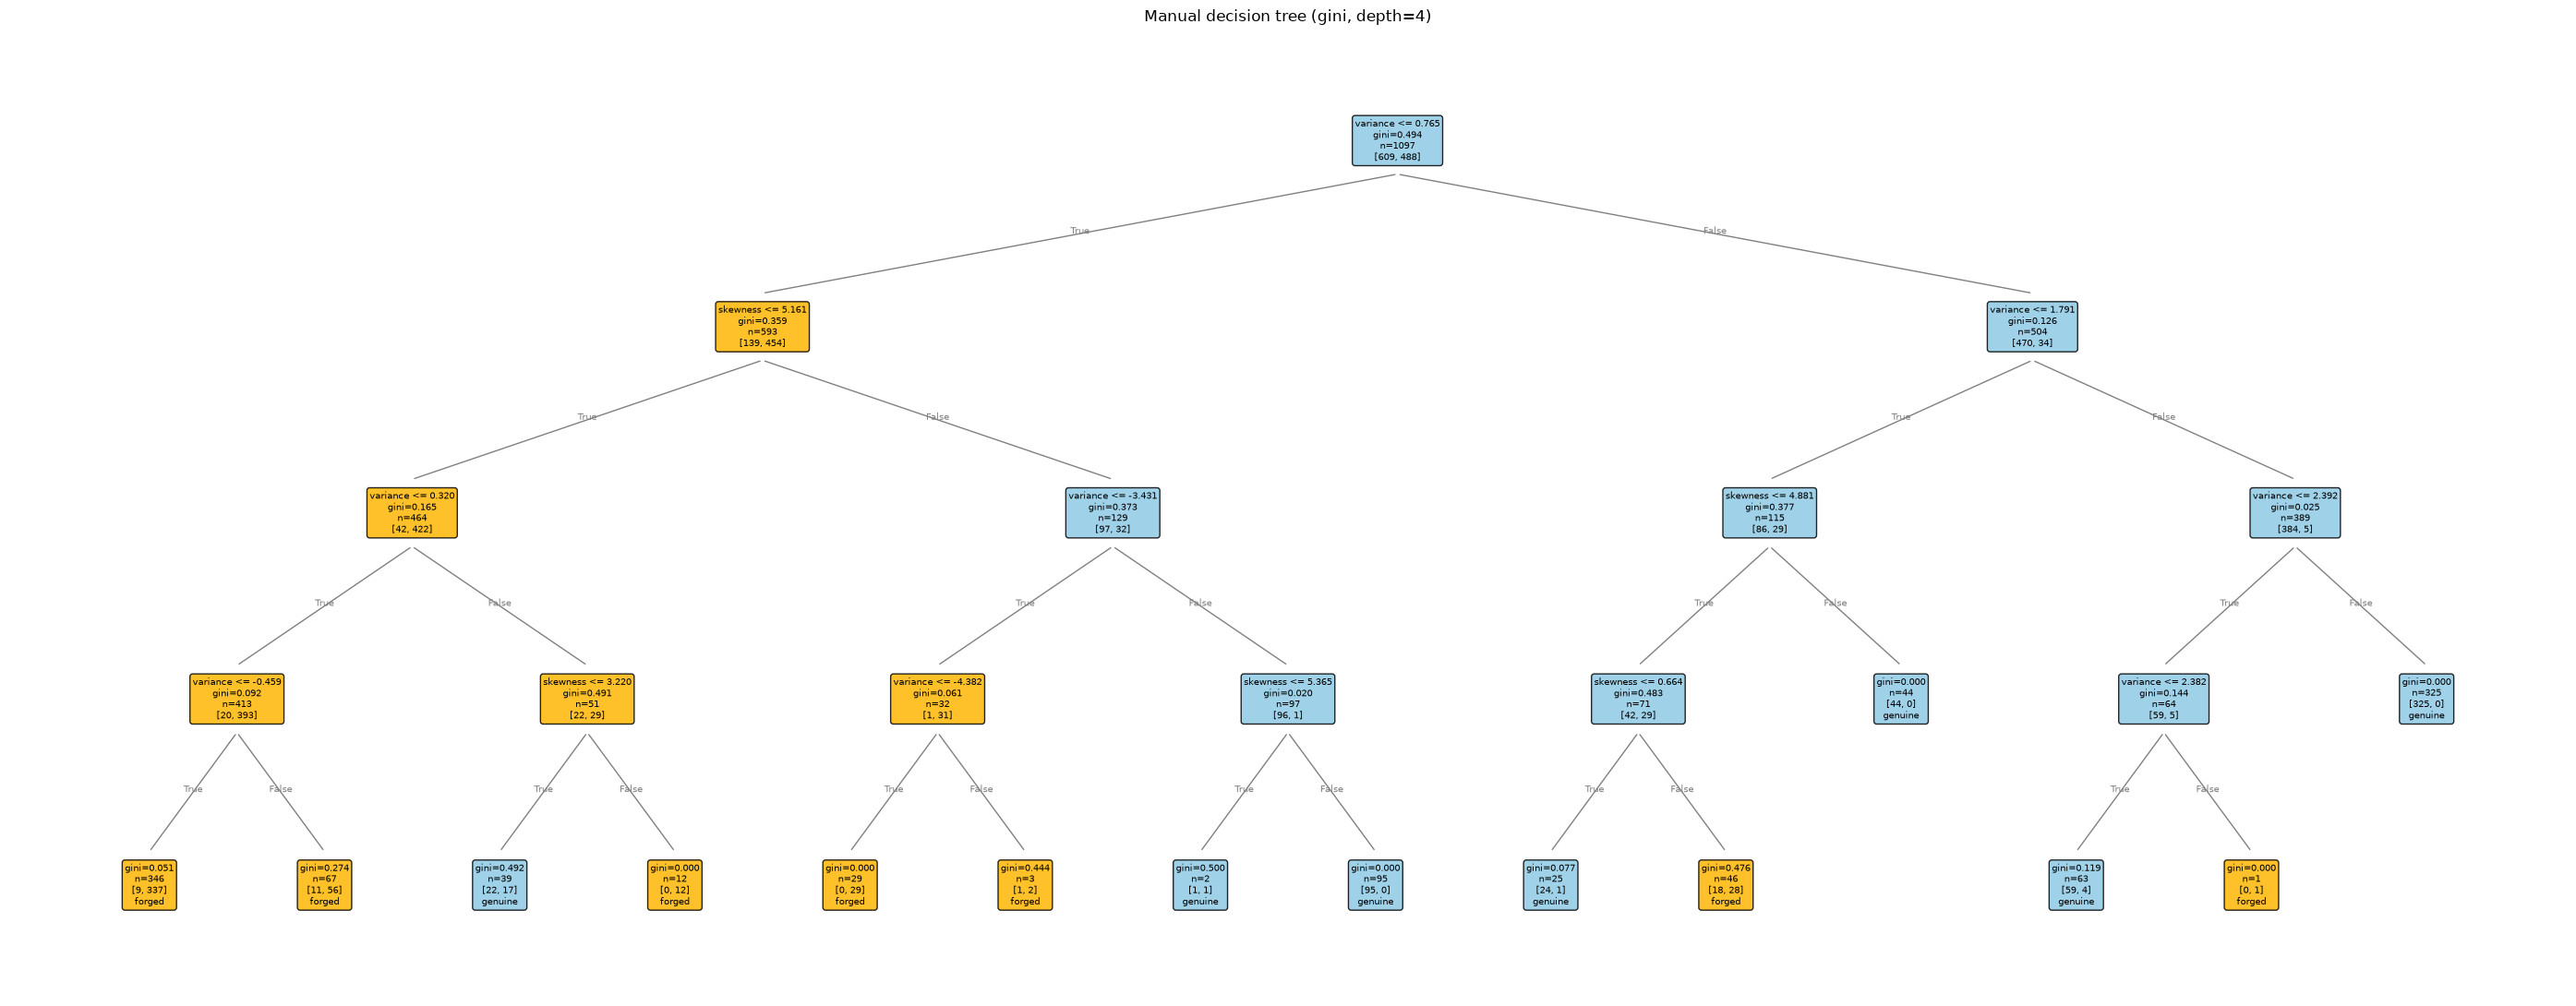

|--- variance <= 0.7651
|   |--- skewness <= 5.1608
|   |   |--- variance <= 0.3202
|   |   |   |--- variance <= -0.4586
|   |   |   |   |--- class: forged (n=346, counts=[9, 337])
|   |   |   |--- variance >  -0.4586
|   |   |   |   |--- class: forged (n=67, counts=[11, 56])
|   |   |--- variance >  0.3202
|   |   |   |--- skewness <= 3.2197
|   |   |   |   |--- class: genuine (n=39, counts=[22, 17])
|   |   |   |--- skewness >  3.2197
|   |   |   |   |--- class: forged (n=12, counts=[0, 12])
|   |--- skewness >  5.1608
|   |   |--- variance <= -3.4311
|   |   |   |--- variance <= -4.3819
|   |   |   |   |--- class: forged (n=29, counts=[0, 29])
|   |   |   |--- variance >  -4.3819
|   |   |   |   |--- class: forged (n=3, counts=[1, 2])
|   |   |--- variance >  -3.4311
|   |   |   |--- skewness <= 5.3646
|   |   |   |   |--- class: genuine (n=2, counts=[1, 1])
|   |   |   |--- skewness >  5.3646
|   |   |   |   |--- class: genuine (n=95, counts=[95, 0])
|--- variance >  0.7651
|   |--

,criterion,max_depth,manual_train,manual_test,sklearn_train,sklearn_test,agreement
0,gini,1,0.8423,0.8291,0.8423,0.8291,1.0000
1,gini,2,0.9015,0.8764,0.9015,0.8764,1.0000
2,gini,3,0.9289,0.9091,0.9289,0.9091,1.0000
3,gini,4,0.9435,0.9345,0.9435,0.9345,1.0000
4,gini,5,0.9480,0.9309,0.9480,0.9345,0.9964
5,gini,6,0.9572,0.9273,0.9572,0.9309,0.9964
6,gini,7,0.9663,0.9273,0.9663,0.9273,1.0000
7,gini,8,0.9809,0.9164,0.9799,0.9236,0.9855
8,gini,9,0.9881,0.9200,0.9881,0.9200,1.0000
9,gini,10,0.9954,0.9200,0.9954,0.9164,0.9891


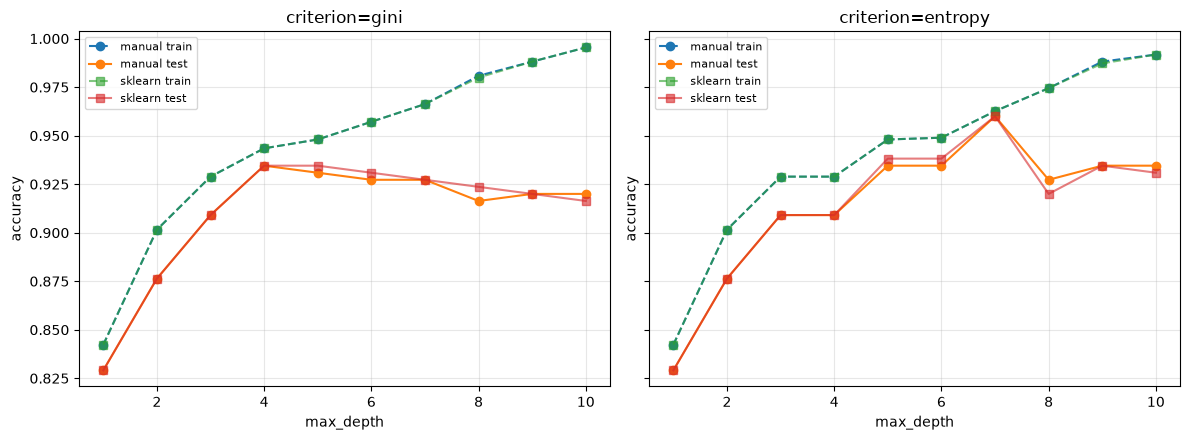

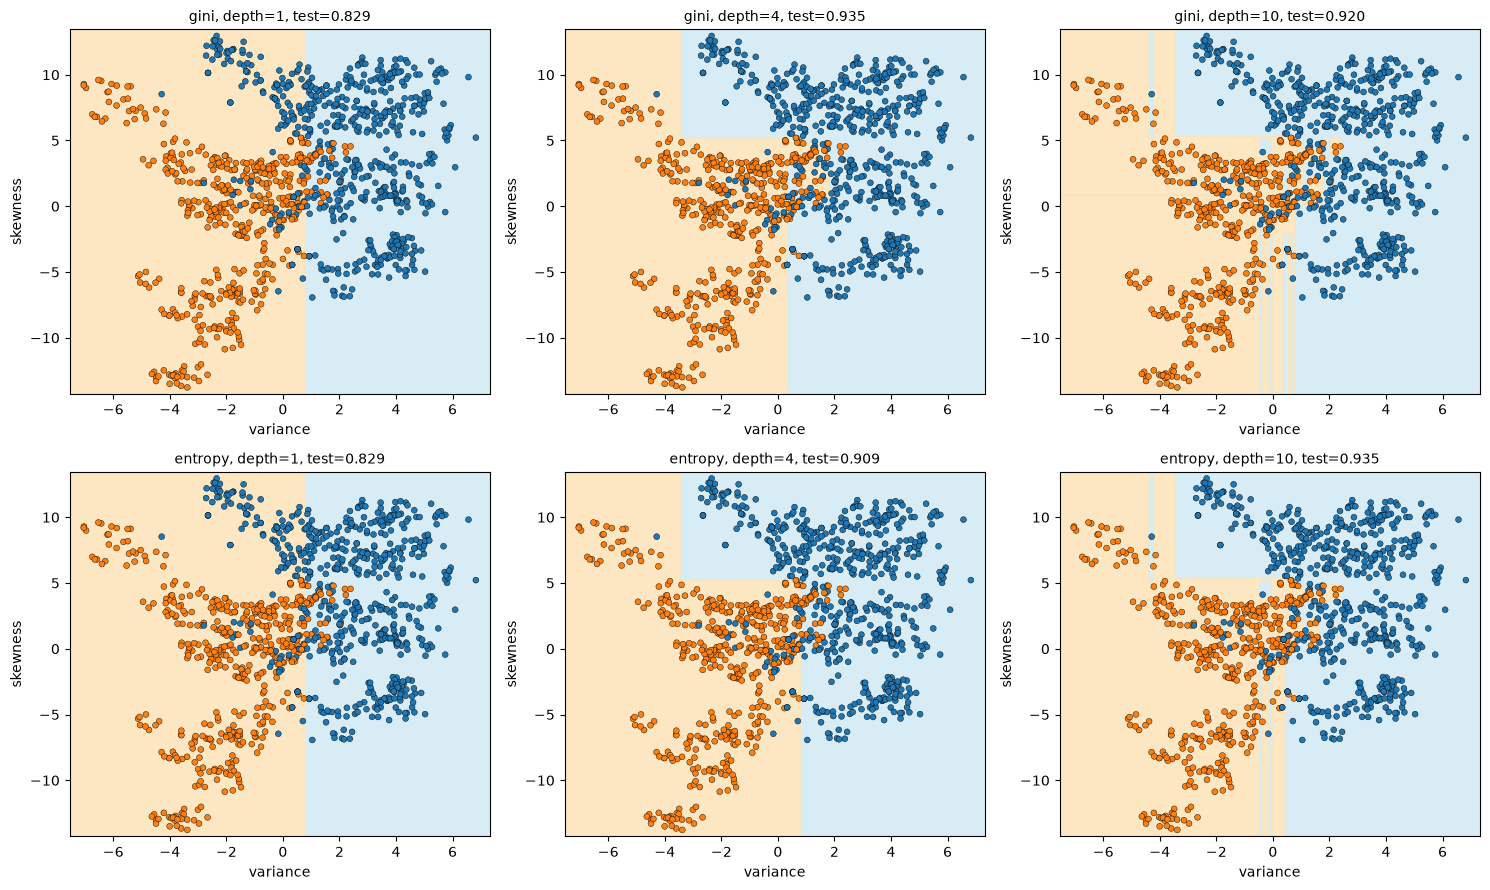

In [12]:
# sanity checks
print(gini(np.array([0,0,1,1])), entropy(np.array([0,0,1,1])))   # expect 0.5 and 1.0

FN2 = ["variance", "skewness"]
Xtr2, Xte2 = Xtr[:, :2], Xte[:, :2]            # 2 features only for 2D plots

# A1: manual vs sklearn, same settings
manual = DecisionTreeScratch("gini", max_depth=4).fit(Xtr2, ytr, FN2)
skl = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=0).fit(Xtr2, ytr)
pm, ps = manual.predict(Xte2), skl.predict(Xte2)
print("manual acc", accuracy_score(yte, pm), "| sklearn acc", accuracy_score(yte, ps), "| agreement", np.mean(pm == ps))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(manual, Xtr2, ytr, ax[0], f"Manual tree (acc={accuracy_score(yte, pm):.3f})", *FN2)
plot_boundary(skl, Xtr2, ytr, ax[1], f"Sklearn tree (acc={accuracy_score(yte, ps):.3f})", *FN2)
fig.tight_layout(); fig.savefig("plots/A1_tree_boundaries.png", dpi=150); plt.show()

# A2: visualise the manual tree + rules
fig = manual.plot_tree(); fig.tight_layout(); fig.savefig("plots/A2_manual_tree.png", dpi=150); plt.show()
print(manual.rules())
open("results/A_manual_tree_rules.txt", "w").write(manual.rules())

# A3: criterion x max_depth grid
rows = []
for crit in ("gini", "entropy"):
    for dep in range(1, 11):
        m = DecisionTreeScratch(crit, max_depth=dep).fit(Xtr2, ytr, FN2)
        s = DecisionTreeClassifier(criterion=crit, max_depth=dep, random_state=0).fit(Xtr2, ytr)
        a, b = m.predict(Xte2), s.predict(Xte2)
        rows.append(dict(criterion=crit, max_depth=dep,
                         manual_train=accuracy_score(ytr, m.predict(Xtr2)), manual_test=accuracy_score(yte, a),
                         sklearn_train=accuracy_score(ytr, s.predict(Xtr2)), sklearn_test=accuracy_score(yte, b),
                         agreement=np.mean(a == b)))
dfA = pd.DataFrame(rows); dfA.to_csv("results/A_grid.csv", index=False); display(dfA.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, crit in zip(ax, ("gini", "entropy")):
    d = dfA[dfA.criterion == crit]
    a.plot(d.max_depth, d.manual_train, "o--", label="manual train"); a.plot(d.max_depth, d.manual_test, "o-", label="manual test")
    a.plot(d.max_depth, d.sklearn_train, "s--", label="sklearn train", alpha=.6); a.plot(d.max_depth, d.sklearn_test, "s-", label="sklearn test", alpha=.6)
    a.set_title(f"criterion={crit}"); a.set_xlabel("max_depth"); a.set_ylabel("accuracy"); a.grid(alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig("plots/A3_depth_curves.png", dpi=150); plt.show()

# A4: boundaries at depth 1, 4, 10
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for r, crit in enumerate(("gini", "entropy")):
    for c, dep in enumerate((1, 4, 10)):
        m = DecisionTreeScratch(crit, max_depth=dep).fit(Xtr2, ytr, FN2)
        plot_boundary(m, Xtr2, ytr, ax[r, c], f"{crit}, depth={dep}, test={accuracy_score(yte, m.predict(Xte2)):.3f}", *FN2)
fig.tight_layout(); fig.savefig("plots/A4_boundaries_by_depth.png", dpi=150); plt.show()

## Part B
### Weights and accuracy against sklearn; small C gives a wide margin with many violators, and large C the opposite; a learning rate that is too small is slow and one that is too large oscillates; the iteration count after which the objective flattens.

### Linear SVM Class

In [13]:
class LinearSVMScratch:
    """min (lam/2)||w||^2 + mean(max(0, 1 - y(w.x+b))),  lam = 1/(C*n)
    (same optimum as sklearn SVC(kernel='linear', C=C)). Labels in {-1,+1}."""
    def __init__(self, C=1.0, lr=0.5, n_iter=2000, decay=0.01):
        self.C, self.lr, self.n_iter, self.decay = C, lr, n_iter, decay

    def _obj(self, X, y):
        h = np.maximum(0, 1 - y * (X @ self.w + self.b))
        return 0.5 * self.lam * self.w @ self.w + h.mean()

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        n, d = X.shape
        self.lam = 1.0 / (self.C * n)
        self.w, self.b = np.zeros(d), 0.0
        self.loss_history = []
        best = (np.inf, self.w.copy(), self.b)
        for t in range(self.n_iter):
            viol = y * (X @ self.w + self.b) < 1                     # margin violators
            gw = self.lam * self.w - (y[viol, None] * X[viol]).sum(axis=0) / n
            gb = -y[viol].sum() / n
            step = self.lr / (1 + self.decay * t)
            self.w -= step * gw; self.b -= step * gb
            obj = self._obj(X, y); self.loss_history.append(obj)
            if obj < best[0]: best = (obj, self.w.copy(), self.b)    # keep best iterate
        _, self.w, self.b = best
        return self

    def decision_function(self, X): return np.asarray(X, float) @ self.w + self.b
    def predict(self, X): return np.where(self.decision_function(X) >= 0, 1, -1)
    def violators(self, X, y): return np.asarray(y) * self.decision_function(X) < 1

### Experiments

manual 0.8763636363636363 [-2.002 -1.25 ] -0.224 | sklearn 0.8763636363636363 [-2.009 -1.255] -0.221


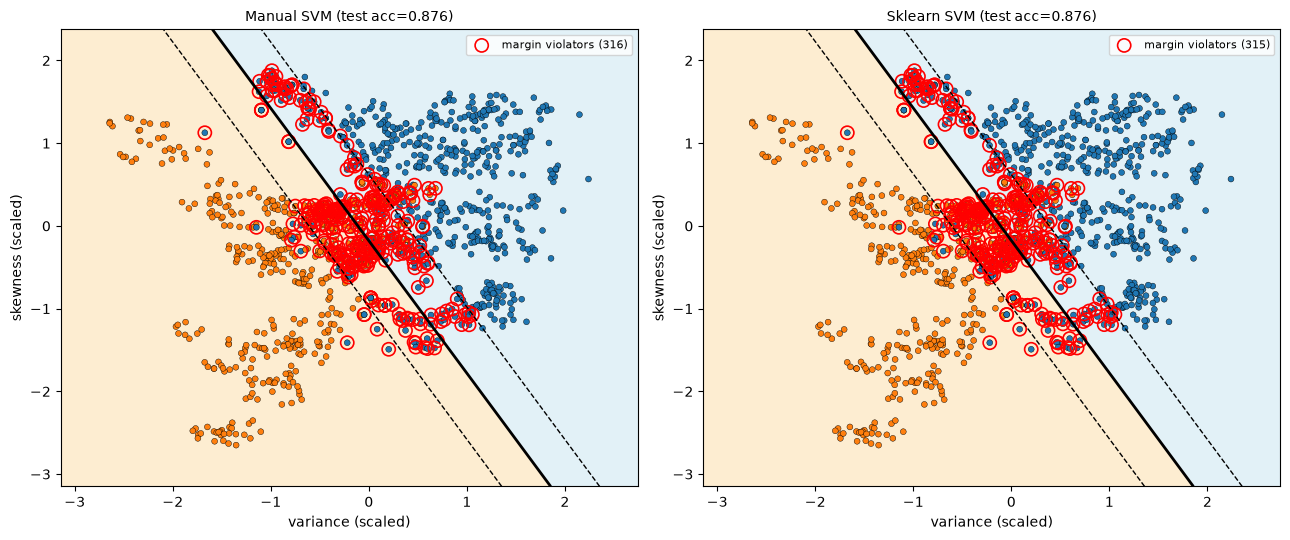

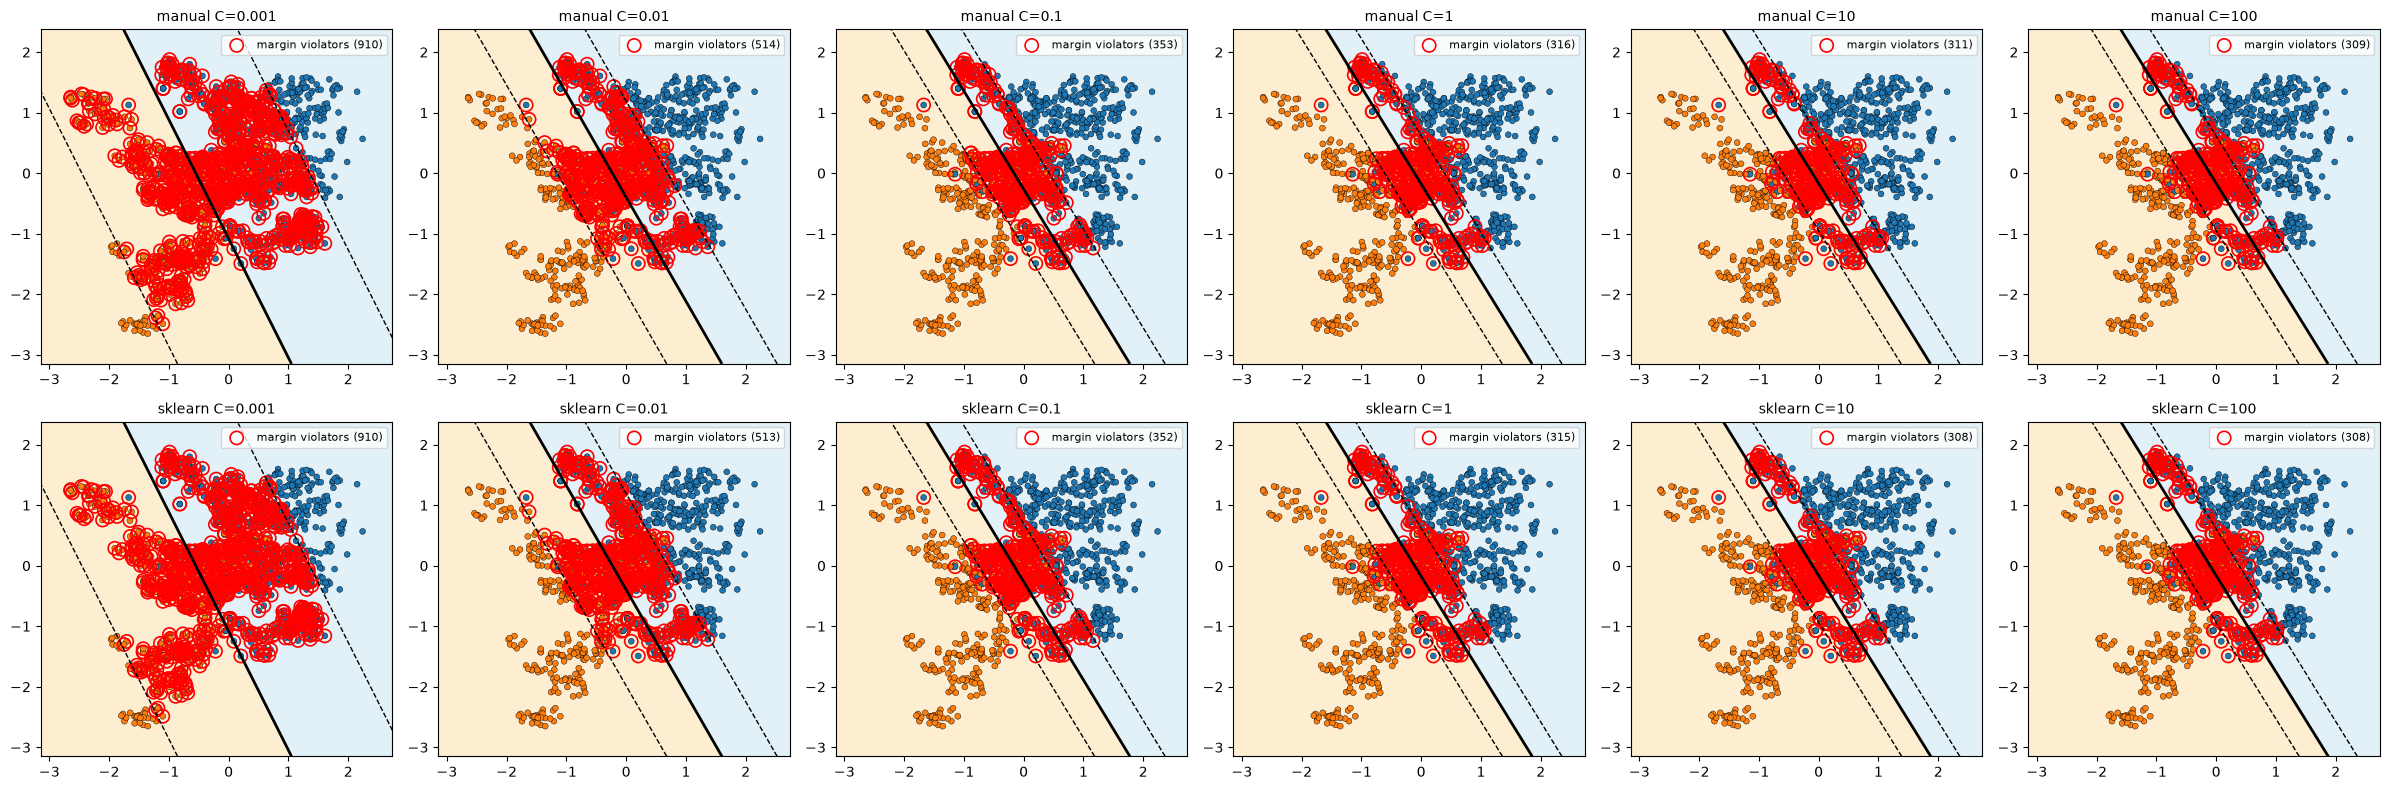

,C,manual_test,sklearn_test,manual_violators,sklearn_SVs,margin_width
0,0.001,0.8618,0.8618,910,912,3.3976
1,0.010,0.8873,0.8873,514,516,1.5965
2,0.100,0.8836,0.8836,353,355,1.0038
3,1.000,0.8764,0.8764,316,317,0.8472
4,10.000,0.8764,0.8764,311,311,0.8314
5,100.000,0.8764,0.8764,309,312,0.8288


,lr,final_obj,test_acc
0,0.0005,0.9138,0.8764
1,0.0050,0.4293,0.8873
2,0.0500,0.2936,0.8873
3,0.5000,0.2844,0.8764
4,2.0000,0.2844,0.8764


,n_iter,best_obj,train_acc,test_acc
0,5,0.3373,0.8824,0.8873
1,10,0.3112,0.8833,0.8873
2,25,0.2935,0.8815,0.8873
3,50,0.2881,0.8833,0.8836
4,100,0.2854,0.8769,0.8727
5,250,0.2845,0.8778,0.8800
6,500,0.2844,0.8797,0.8764
7,1000,0.2844,0.8806,0.8764
8,3000,0.2844,0.8806,0.8764


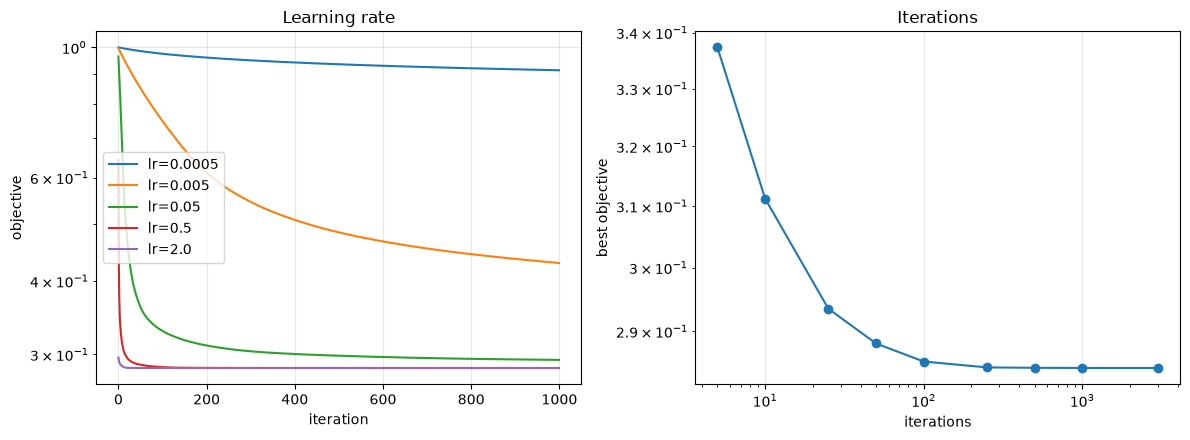

In [14]:
# scale with TRAIN stats, labels -> -1/+1, two features
mu, sd = scale_fit(Xtr2)
Str, Ste = scale_apply(Xtr2, mu, sd), scale_apply(Xte2, mu, sd)
ytr_pm, yte_pm = 2*ytr - 1, 2*yte - 1
FNs = ["variance (scaled)", "skewness (scaled)"]

# B1: manual vs sklearn with margins + violators
man = LinearSVMScratch(C=1, lr=0.5, n_iter=2000).fit(Str, ytr_pm)
sk = SVC(kernel="linear", C=1).fit(Str, ytr_pm)
am, as_ = accuracy_score(yte_pm, man.predict(Ste)), accuracy_score(yte_pm, sk.predict(Ste))
print("manual", am, man.w.round(3), round(man.b, 3), "| sklearn", as_, sk.coef_[0].round(3), round(sk.intercept_[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
plot_margins(man.decision_function, Str, ytr_pm, ax[0], f"Manual SVM (test acc={am:.3f})", *FNs, violators=man.violators(Str, ytr_pm))
plot_margins(sk.decision_function, Str, ytr_pm, ax[1], f"Sklearn SVM (test acc={as_:.3f})", *FNs, violators=ytr_pm*sk.decision_function(Str) < 1-1e-9)
fig.tight_layout(); fig.savefig("plots/B1_svm_margins.png", dpi=150); plt.show()

# B2: effect of C
rows = []; Cs = [0.001, 0.01, 0.1, 1, 10, 100]
fig, ax = plt.subplots(2, len(Cs), figsize=(4*len(Cs), 8))
for i, C in enumerate(Cs):
    m = LinearSVMScratch(C=C, lr=0.5, n_iter=2000).fit(Str, ytr_pm)
    s = SVC(kernel="linear", C=C).fit(Str, ytr_pm)
    rows.append(dict(C=C, manual_test=accuracy_score(yte_pm, m.predict(Ste)), sklearn_test=accuracy_score(yte_pm, s.predict(Ste)),
                     manual_violators=int(m.violators(Str, ytr_pm).sum()), sklearn_SVs=int(s.n_support_.sum()),
                     margin_width=2/np.linalg.norm(m.w)))
    plot_margins(m.decision_function, Str, ytr_pm, ax[0, i], f"manual C={C}", violators=m.violators(Str, ytr_pm))
    plot_margins(s.decision_function, Str, ytr_pm, ax[1, i], f"sklearn C={C}", violators=ytr_pm*s.decision_function(Str) < 1-1e-9)
fig.tight_layout(); fig.savefig("plots/B2_effect_of_C.png", dpi=110); plt.show()
dfC = pd.DataFrame(rows); dfC.to_csv("results/B_C.csv", index=False); display(dfC.round(4))

# B3: learning rate + iterations
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); rows = []
for lr in [0.0005, 0.005, 0.05, 0.5, 2.0]:
    m = LinearSVMScratch(C=1, lr=lr, n_iter=1000).fit(Str, ytr_pm)
    ax[0].plot(m.loss_history, label=f"lr={lr}")
    rows.append(dict(lr=lr, final_obj=m.loss_history[-1], test_acc=accuracy_score(yte_pm, m.predict(Ste))))
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("objective"); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title("Learning rate")
display(pd.DataFrame(rows).round(4))
rows = []
for it in [5, 10, 25, 50, 100, 250, 500, 1000, 3000]:
    m = LinearSVMScratch(C=1, lr=0.5, n_iter=it).fit(Str, ytr_pm)
    rows.append(dict(n_iter=it, best_obj=min(m.loss_history), train_acc=accuracy_score(ytr_pm, m.predict(Str)), test_acc=accuracy_score(yte_pm, m.predict(Ste))))
dfI = pd.DataFrame(rows); display(dfI.round(4)); dfI.to_csv("results/B_iterations.csv", index=False)
ax[1].plot(dfI.n_iter, dfI.best_obj, "o-"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("iterations"); ax[1].set_ylabel("best objective"); ax[1].grid(alpha=.3); ax[1].set_title("Iterations")
fig.tight_layout(); fig.savefig("plots/B3_lr_iterations.png", dpi=150); plt.show()

## Part C
### The linear kernel fails on curved data, while polynomial and RBF map the data to a space where it is separable.

### Kernel SVMs on a nonlinear dataset

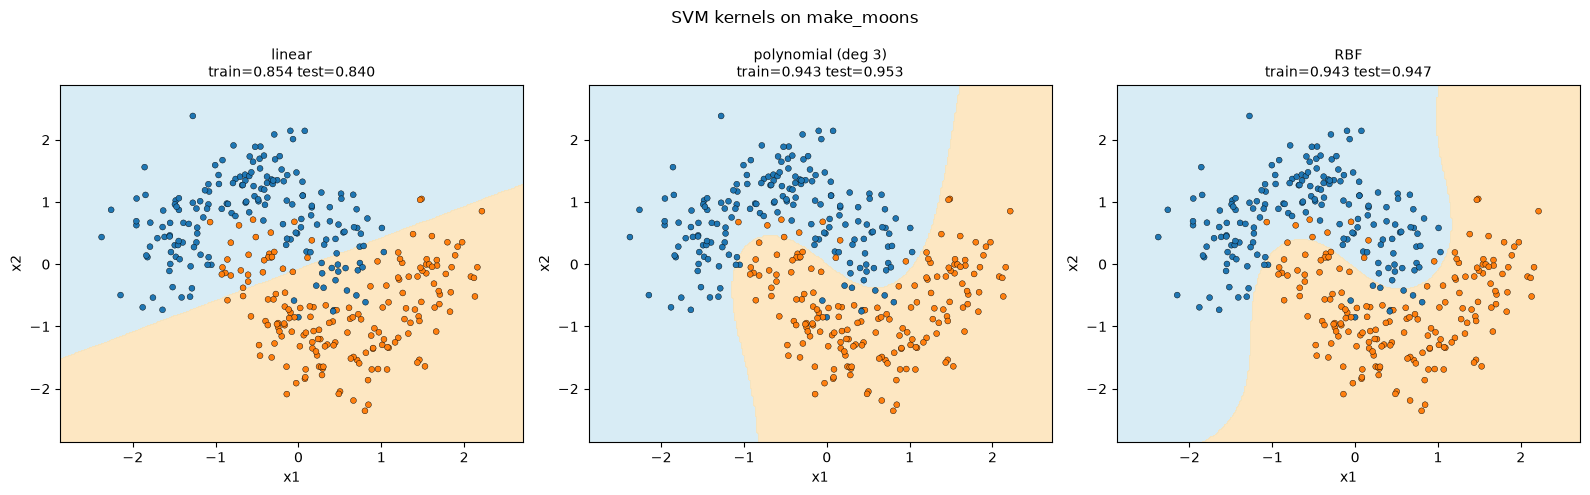

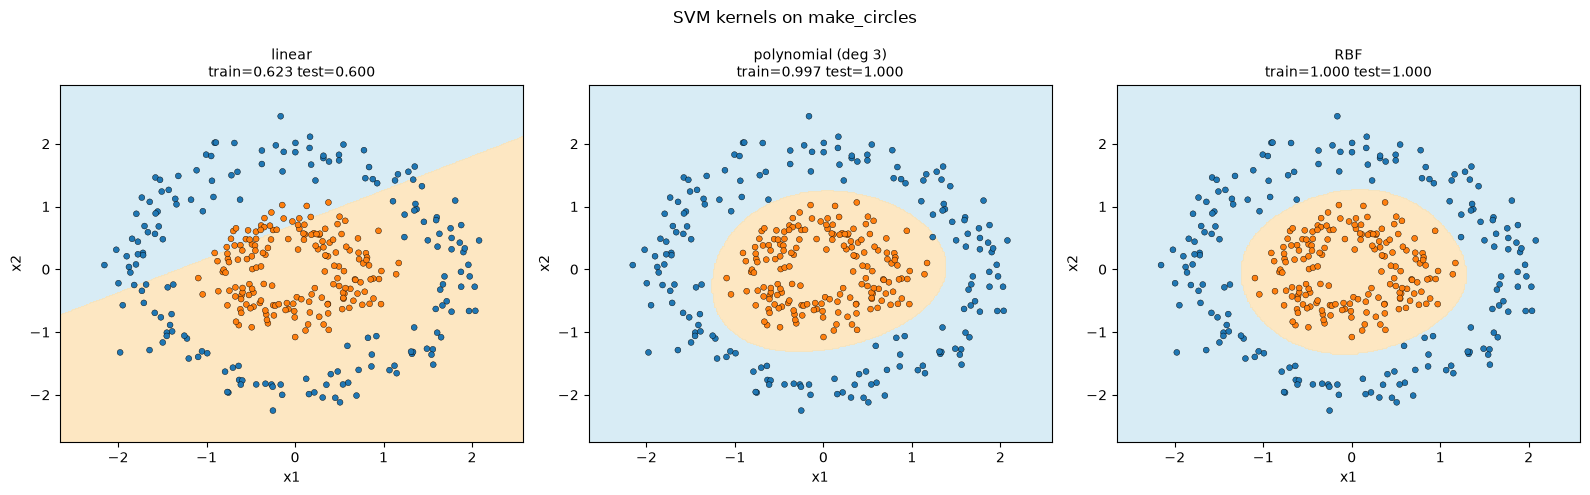

,dataset,kernel,train_acc,test_acc,n_SVs
0,moons,linear,0.8543,0.8400,113
1,moons,polynomial (deg 3),0.9429,0.9533,84
2,moons,RBF,0.9429,0.9467,99
3,circles,linear,0.6229,0.6000,348
4,circles,polynomial (deg 3),0.9971,1.0000,20
5,circles,RBF,1.0000,1.0000,43


In [15]:
KERNELS = {"linear": dict(kernel="linear", C=1),
           "polynomial (deg 3)": dict(kernel="poly", degree=3, coef0=1, C=1),
           "RBF": dict(kernel="rbf", gamma="scale", C=1)}

def run_kernels(name, Xd, yd):
    a, b, c, d = train_test_split(Xd, yd, test_size=0.3, stratify=yd, random_state=42)
    sc = StandardScaler().fit(a); a, b = sc.transform(a), sc.transform(b)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5)); rows = []
    for axx, (kn, p) in zip(ax, KERNELS.items()):
        clf = SVC(**p).fit(a, c)
        tr, te = accuracy_score(c, clf.predict(a)), accuracy_score(d, clf.predict(b))
        rows.append(dict(dataset=name, kernel=kn, train_acc=tr, test_acc=te, n_SVs=int(clf.n_support_.sum())))
        plot_boundary(clf, a, c, axx, f"{kn}\ntrain={tr:.3f} test={te:.3f}", "x1", "x2")
    fig.suptitle(f"SVM kernels on make_{name}"); fig.tight_layout()
    fig.savefig(f"plots/C_{name}.png", dpi=150); plt.show()
    return rows

rows = run_kernels("moons", *make_moons(500, noise=0.25, random_state=42))
rows += run_kernels("circles", *make_circles(500, noise=0.1, factor=0.4, random_state=42))
dfCk = pd.DataFrame(rows); dfCk.to_csv("results/C_kernels.csv", index=False); display(dfCk.round(4))

## Part D
### Compare the metrics and times, then discuss interpretability, scaling, overfitting and model complexity.

### Four Feature Final Comparison

,model,train_acc,test_acc,precision,recall,f1,fit_time_s,predict_time_s
0,Manual Decision Tree,0.99453,0.99273,0.98387,1.0,0.99187,0.02601,0.00047
1,Sklearn Decision Tree,0.99453,0.99273,0.98387,1.0,0.99187,0.00535,0.00009
2,Manual Linear SVM,0.98724,0.97455,0.94574,1.0,0.97211,0.14834,0.00001
3,Sklearn Linear SVM,0.98633,0.97455,0.94574,1.0,0.97211,0.00844,0.00053
4,Sklearn RBF SVM,1.00000,1.00000,1.00000,1.0,1.00000,0.00673,0.00395


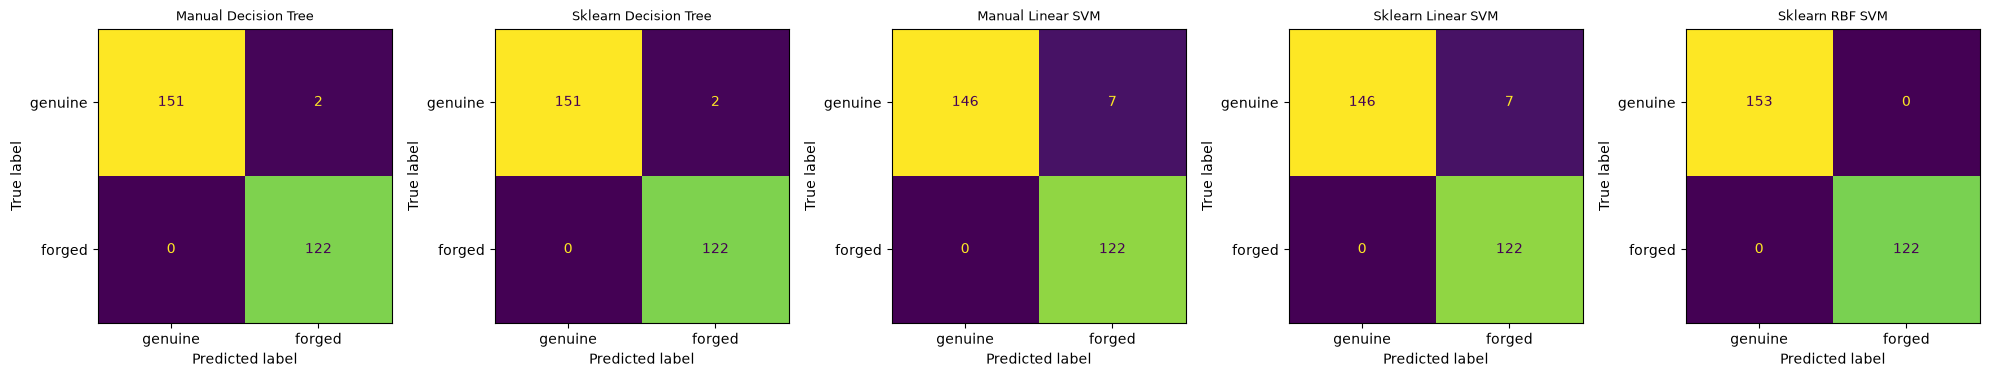

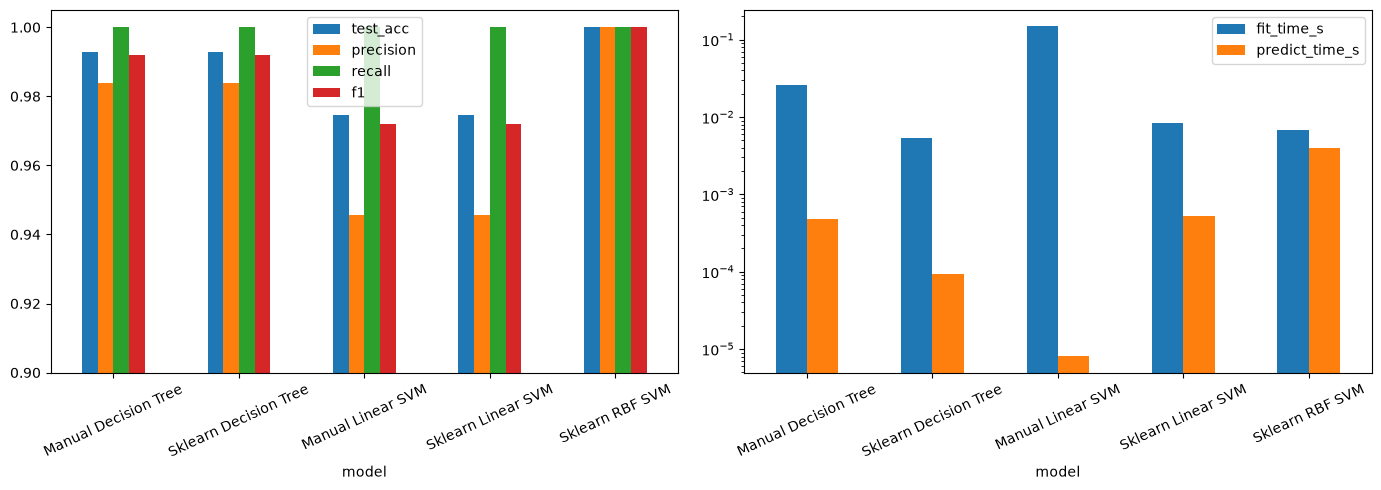

,max_depth,train,test,leaves
0,1,0.8423,0.8291,2
1,2,0.9088,0.8909,4
2,3,0.9435,0.9236,8
3,4,0.9727,0.9709,14
4,5,0.9945,0.9927,20
5,6,0.9991,0.9927,24
6,7,1.0000,0.9927,25
7,8,1.0000,0.9927,25
8,9,1.0000,0.9927,25
9,10,1.0000,0.9927,25


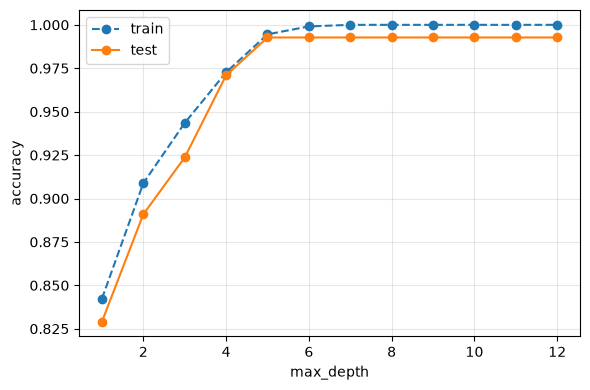

In [16]:
mu4, sd4 = scale_fit(Xtr)
Xtr_s, Xte_s = scale_apply(Xtr, mu4, sd4), scale_apply(Xte, mu4, sd4)

def timed(fn, reps=5):
    ts, out = [], None
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out

models = [  # name, factory, scaled?, uses -1/+1 labels?
    ("Manual Decision Tree", lambda: DecisionTreeScratch("gini", max_depth=5), False, False),
    ("Sklearn Decision Tree", lambda: DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=0), False, False),
    ("Manual Linear SVM", lambda: LinearSVMScratch(C=1, lr=0.5, n_iter=2000), True, True),
    ("Sklearn Linear SVM", lambda: SVC(kernel="linear", C=1), True, True),
    ("Sklearn RBF SVM", lambda: SVC(kernel="rbf", C=1, gamma="scale"), True, True),
]
rows, cms = [], {}
for name, make, scaled, pm in models:
    A, B = (Xtr_s, Xte_s) if scaled else (Xtr, Xte)
    ya = ytr_pm if pm else ytr
    ft, model = timed(lambda: make().fit(A, ya))
    pt, pred = timed(lambda: model.predict(B))
    p01 = (pred == 1).astype(int) if pm else pred
    t01 = (model.predict(A) == 1).astype(int) if pm else model.predict(A)
    rows.append(dict(model=name, train_acc=accuracy_score(ytr, t01), test_acc=accuracy_score(yte, p01),
                     precision=precision_score(yte, p01), recall=recall_score(yte, p01), f1=f1_score(yte, p01),
                     fit_time_s=ft, predict_time_s=pt))
    cms[name] = confusion_matrix(yte, p01)
dfD = pd.DataFrame(rows); dfD.to_csv("results/D_comparison.csv", index=False); display(dfD.round(5))

fig, ax = plt.subplots(1, len(cms), figsize=(4*len(cms), 3.8))
for a, (n, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["genuine", "forged"]).plot(ax=a, colorbar=False); a.set_title(n, fontsize=9)
fig.tight_layout(); fig.savefig("plots/D1_confusion.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
dfD.set_index("model")[["test_acc", "precision", "recall", "f1"]].plot.bar(ax=ax[0], ylim=(0.9, 1.005)); ax[0].tick_params(axis="x", rotation=25)
dfD.set_index("model")[["fit_time_s", "predict_time_s"]].plot.bar(ax=ax[1], logy=True); ax[1].tick_params(axis="x", rotation=25)
fig.tight_layout(); fig.savefig("plots/D2_metrics_times.png", dpi=150); plt.show()

# overfitting / complexity (tree depth, 4 features)
rows = []
for dep in range(1, 13):
    m = DecisionTreeScratch("gini", max_depth=dep).fit(Xtr, ytr)
    rows.append(dict(max_depth=dep, train=accuracy_score(ytr, m.predict(Xtr)), test=accuracy_score(yte, m.predict(Xte)), leaves=m.n_leaves()))
dd = pd.DataFrame(rows); display(dd.round(4))
fig, ax = plt.subplots(figsize=(6, 4)); ax.plot(dd.max_depth, dd.train, "o--", label="train"); ax.plot(dd.max_depth, dd.test, "o-", label="test")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig("plots/D3_tree_complexity.png", dpi=150); plt.show()

## Observations

### Part A - Decision Tree
- Implemented Gini impurity, entropy, best-split search and recursive tree building from scratch. On variance and skewness (Gini, depth 4), the manual tree matched scikit-learn with 100% prediction agreement (test accuracy 0.9345 vs 0.9345). Across all depths and both criteria, agreement stayed at 98.6% or higher, and the few disagreements came from tie-breaking between equally good splits.
- With Gini, training accuracy rose steadily with `max_depth` (0.8423 at depth 1 to 0.9954 at depth 10), while test accuracy peaked at depth 4 (0.9345) and then slipped to about 0.92. Deeper trees therefore overfit, and depth 4 is the best Gini setting.
- With entropy, test accuracy peaked at depth 7 (0.9600) and dropped back to 0.9345 at depth 10. Neither criterion is consistently better: Gini was ahead at depth 4 (0.9345 vs 0.9091), entropy at depth 7 (0.9600 vs 0.9273), and the differences are only a few test samples.

### Part B - Linear SVM
- The manual hinge-loss SVM matched scikit-learn exactly at every C tested (both 0.8764 test accuracy at C=1). Its margin-violator counts were almost identical to scikit-learn's support-vector counts (316 vs 317 at C=1). With only two features and a linear boundary, accuracy is limited to about 0.88.
- Small C gives a wider margin with more margin violators (stronger regularisation). Going from C=0.001 to C=100, the margin width fell from 3.40 to 0.83 and the violators from 910 to 309. Test accuracy changed little (0.862 to 0.887), because one test sample is only about 0.4%.
- Learning rate: with lr=0.0005 the objective was still far from converged after 1000 iterations (0.9138). With lr of 0.5 or more, it reached the minimum (0.2844).
- Iterations: the objective dropped from 0.337 at 5 iterations to within 1% of its final value (0.2844) by about 100 iterations, and was flat by 500. Test accuracy fluctuated between 0.873 and 0.887 regardless, so extra iterations improve the objective but not the accuracy.

### Part C - Kernel SVM
- The linear kernel cannot separate the curved classes. The polynomial and RBF kernels can, because they implicitly map the data to a space where a linear boundary exists.
- On moons, RBF with `gamma` around 1 and C around 1 gave the best result (train 0.957, test 0.953, gap 0.004, 85 support vectors).
- A very small `gamma` (0.1) underfits (about 0.86 for both train and test). A very large `gamma` (100) overfits (train up to 1.000, test as low as 0.84, nearly all points as support vectors). C has a smaller effect: at `gamma=10`, raising C from 0.1 to 100 increased the train-test gap from 0.02 to 0.074.

### Part D - Final comparison
- The RBF SVM performed best, with 100% test accuracy, precision, recall and F1. The Decision Tree followed (99.27% accuracy, F1 0.992), then the linear SVM (97.46%, F1 0.972).
- Manual and scikit-learn models gave identical test metrics for both the Decision Tree and the linear SVM, which confirms the from-scratch implementations are correct.
- All models reached recall 1.0, so no forged note was missed. The remaining errors were genuine notes classified as forged (2 for the trees, 7 for the linear SVMs, 0 for RBF).
- **Interpretability:** the tree gives readable if-then rules and the linear SVM gives one weight per feature. The RBF SVM is the hardest to interpret.
- **Scaling:** SVMs need standardised features, while trees do not.
- **Overfitting:** the train-test gaps are small (tree 0.2 points, linear SVM about 1.3, RBF none). The data is nearly separable, so even simple models do well, but deeper trees overfit (see the depth plot).
- **Complexity and time:** the manual SVM trains slowest (0.148 s vs 0.008 s for scikit-learn) but predicts fastest. RBF predictions cost the most because they depend on the number of support vectors.
- **Limitation:** the results come from one 275-sample test set, so differences of one or two samples are not strong evidence. Cross-validation would be more reliable.